# Stage 8A – Embedding and Centroid Diagnostic

**Purpose:** Diagnose why the Stage 6 clean-embedding Euclidean distances appear much larger than the manuscript threshold of 0.4.

This is a diagnostic notebook only. It does **not** change the manuscript formula, tune the threshold, retrain the model, or claim detection performance.

The manuscript defines:
- \(H=GCN(A,F)\) (Section 3.3)
- \(S_i=\|h_i-\mu\|_2\), where \(\mu\) is the mean embedding of clean samples (Section 3.4)
- adversarial if \(S_i>\tau\), with \(	au=0.4\) in Table 3 (Section 4.4)

The manuscript does not specify whether the centroid uses clean training samples only or all clean samples. This notebook reports both as diagnostics and does not silently choose between them.

**Inputs required:** only the Stage 5 Graph Outputs ZIP and Stage 6 DGI Outputs ZIP.

## 1. Upload the Stage 5 and Stage 6 ZIP files

In [1]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving Stage5_Graph_Outputs.zip to Stage5_Graph_Outputs.zip
Saving Stage6_DGI_Outputs.zip to Stage6_DGI_Outputs.zip
Uploaded: ['Stage5_Graph_Outputs.zip', 'Stage6_DGI_Outputs.zip']


## 2. Imports and extraction

In [2]:
import os, json, zipfile, io
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

WORK = Path("/content/stage8a_diagnostic")
WORK.mkdir(parents=True, exist_ok=True)

def find_zip(keyword):
    found=[n for n in uploaded if n.lower().endswith(".zip") and keyword.lower() in n.lower()]
    if len(found)!=1:
        raise FileNotFoundError(f"Expected one uploaded ZIP containing '{keyword}', found: {found}")
    return found[0]

def extract(zip_name, folder):
    dest=WORK/folder
    dest.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(zip_name) as z:
        for info in z.infolist():
            target=(dest/info.filename).resolve()
            if not str(target).startswith(str(dest.resolve())):
                raise ValueError("Unsafe ZIP path")
        z.extractall(dest)
    return dest

S5=extract(find_zip("Stage5"),"stage5")
S6=extract(find_zip("Stage6"),"stage6")

def find_one(root,name):
    hits=list(Path(root).rglob(name))
    if len(hits)!=1:
        raise FileNotFoundError(f"Expected one {name}; found {len(hits)}")
    return hits[0]

Device: cpu


## 3. Load Stage 5 graph features, adjacency and split masks

In [3]:
feat_file=find_one(S5,"graph_node_features_and_masks.npz")
with np.load(feat_file,allow_pickle=True) as z:
    F_clean=z["node_features"].astype(np.float32)
    labels=z["labels"]
    train_mask=z["train_mask"].astype(bool)
    val_mask=z["validation_mask"].astype(bool)
    test_mask=z["test_mask"].astype(bool)

A=sp.load_npz(find_one(S5,"cosine_knn_adjacency.npz")).tocsr().astype(np.float32)
N,D=F_clean.shape
assert (N,D)==(6400,128)
assert A.shape==(N,N)
assert train_mask.sum()==4480 and val_mask.sum()==960 and test_mask.sum()==960
assert np.all(np.isfinite(F_clean))
assert (A-A.T).nnz==0

print("Feature matrix:",F_clean.shape)
print("Adjacency:",A.shape,"undirected edges:",A.nnz//2)
print("Train/validation/test:",train_mask.sum(),val_mask.sum(),test_mask.sum())

Feature matrix: (6400, 128)
Adjacency: (6400, 6400) undirected edges: 43681
Train/validation/test: 4480 960 960


## 4. Load Stage 6 checkpoint and saved embeddings

In [4]:
checkpoint=torch.load(find_one(S6,"stage6_dgi_gcn_model.pt"),
                      map_location=DEVICE,weights_only=True)
print("Checkpoint keys:",list(checkpoint.keys()))

with np.load(find_one(S6,"stage6_dgi_graph_embeddings.npz"),allow_pickle=True) as z:
    H_saved=z["graph_embeddings"].astype(np.float32)
    train_idx=z["train_indices"].astype(np.int64)
    val_idx=z["val_indices"].astype(np.int64)
    test_idx=z["test_indices"].astype(np.int64)

assert H_saved.shape==(N,128)
assert np.array_equal(np.flatnonzero(train_mask),train_idx)
assert np.array_equal(np.flatnonzero(val_mask),val_idx)
assert np.array_equal(np.flatnonzero(test_mask),test_idx)
print("Saved embeddings:",H_saved.shape)

Checkpoint keys: ['encoder.gc1.weight', 'encoder.gc1.bias', 'encoder.gc2.weight', 'encoder.gc2.bias', 'discriminator.weight', 'discriminator.bias']
Saved embeddings: (6400, 128)


## 5. Rebuild the exact Stage 6 encoder and reproduce embeddings

In [5]:
class GraphConvolution(nn.Module):
    def __init__(self,in_features,out_features,bias=True):
        super().__init__()
        self.weight=nn.Parameter(torch.empty(in_features,out_features))
        nn.init.xavier_uniform_(self.weight)
        self.bias=nn.Parameter(torch.zeros(out_features)) if bias else None
    def forward(self,x,adj):
        out=torch.sparse.mm(adj,torch.matmul(x,self.weight))
        if self.bias is not None: out=out+self.bias
        return out

class GCNEncoder(nn.Module):
    def __init__(self,in_dim=128,hidden_dim=128,dropout=0.5):
        super().__init__()
        self.gc1=GraphConvolution(in_dim,hidden_dim)
        self.gc2=GraphConvolution(hidden_dim,hidden_dim)
        self.dropout=dropout
    def forward(self,x,adj,return_intermediate=False):
        h1=self.gc1(x,adj)
        h1_relu=F.relu(h1)
        h_drop=F.dropout(h1_relu,p=self.dropout,training=self.training)
        h2=self.gc2(h_drop,adj)
        if return_intermediate:
            return h1,h1_relu,h2
        return h2

encoder=GCNEncoder().to(DEVICE)
enc_state={k.replace("encoder.","",1):v for k,v in checkpoint.items() if k.startswith("encoder.")}
encoder.load_state_dict(enc_state,strict=True)
encoder.eval()

def normalize_adj(adj):
    ahat=(adj+sp.eye(adj.shape[0],dtype=np.float32,format="csr")).tocsr()
    deg=np.asarray(ahat.sum(axis=1)).ravel()
    inv=np.power(deg,-0.5).astype(np.float32)
    return (sp.diags(inv)@ahat@sp.diags(inv)).tocsr().astype(np.float32)

An=normalize_adj(A)
coo=An.tocoo()
indices=torch.tensor(np.vstack([coo.row,coo.col]),dtype=torch.long,device=DEVICE)
values=torch.tensor(coo.data,dtype=torch.float32,device=DEVICE)
A_t=torch.sparse_coo_tensor(indices,values,coo.shape,device=DEVICE).coalesce()
F_t=torch.tensor(F_clean,dtype=torch.float32,device=DEVICE)

with torch.no_grad():
    H_rebuilt=encoder(F_t,A_t).cpu().numpy()
    h1,h1_relu,h2=encoder(F_t,A_t,return_intermediate=True)
    H_layer1_raw=h1.cpu().numpy()
    H_layer1_relu=h1_relu.cpu().numpy()

maxdiff=float(np.max(np.abs(H_rebuilt-H_saved)))
print("Maximum absolute difference:",maxdiff)
assert maxdiff<1e-4,"Stage 6 embeddings do not reproduce. Stop and share this output."
print("PASS: Stage 6 embeddings reproduced.")

Maximum absolute difference: 0.0
PASS: Stage 6 embeddings reproduced.


/tmp/ipykernel_7254/3426823973.py:42: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  A_t=torch.sparse_coo_tensor(indices,values,coo.shape,device=DEVICE).coalesce()


## 6. Compare feature and representation scales

In [6]:
def describe_matrix(name,X):
    norms=np.linalg.norm(X,axis=1)
    return {"representation":name,"shape":str(X.shape),
            "component_mean":float(X.mean()),"component_std":float(X.std()),
            "row_norm_mean":float(norms.mean()),"row_norm_median":float(np.median(norms)),
            "row_norm_min":float(norms.min()),"row_norm_max":float(norms.max())}

representation_summary=pd.DataFrame([
    describe_matrix("Stage5 CNN node features F",F_clean),
    describe_matrix("GCN first layer before ReLU",H_layer1_raw),
    describe_matrix("GCN first layer after ReLU",H_layer1_relu),
    describe_matrix("Stage6 final GCN output H",H_rebuilt)
])
display(representation_summary)

,representation,shape,component_mean,component_std,row_norm_mean,row_norm_median,row_norm_min,row_norm_max
0,Stage5 CNN node features F,"(6400, 128)",0.234208,0.514714,5.514847,4.465491,0.986093,21.395487
1,GCN first layer before ReLU,"(6400, 128)",-0.018201,0.519122,5.342157,4.723546,1.383265,18.654833
2,GCN first layer after ReLU,"(6400, 128)",0.179360,0.266929,3.348746,3.044808,0.954021,11.110585
3,Stage6 final GCN output H,"(6400, 128)",0.046987,0.294560,3.185935,3.034479,1.229660,8.597555


## 7. Compare possible clean-centroid definitions
Section 3.4 says 'mean embedding of clean samples' but does not state the precise subset. We report training-only and all-clean centroids separately. Neither is silently declared the manuscript's definitive interpretation.

In [7]:
split_masks={"train":train_mask,"validation":val_mask,"test":test_mask,"all_clean":np.ones(N,dtype=bool)}
centroid_rows=[]
score_distributions={}
for rep_name,rep in [
    ("CNN node features F",F_clean),
    ("GCN first layer raw",H_layer1_raw),
    ("GCN first layer ReLU",H_layer1_relu),
    ("Stage6 final GCN H",H_rebuilt)
]:
    for centroid_name,cmask in [("training_clean_centroid",train_mask),
                                ("all_clean_centroid",np.ones(N,dtype=bool))]:
        mu=rep[cmask].mean(axis=0)
        d=np.linalg.norm(rep-mu[None,:],axis=1)
        for split,smask in split_masks.items():
            vals=d[smask]
            centroid_rows.append({
                "representation":rep_name,"centroid":centroid_name,"evaluated_split":split,
                "n":len(vals),"mean_distance":float(vals.mean()),
                "median_distance":float(np.median(vals)),
                "std_distance":float(vals.std()),
                "min_distance":float(vals.min()),
                "p05":float(np.quantile(vals,.05)),
                "p95":float(np.quantile(vals,.95)),
                "max_distance":float(vals.max()),
                "fraction_above_0_4":float(np.mean(vals>0.4))
            })
            score_distributions[(rep_name,centroid_name,split)]=vals

distance_summary=pd.DataFrame(centroid_rows)
display(distance_summary)

,representation,centroid,evaluated_split,n,mean_distance,median_distance,std_distance,min_distance,p05,p95,max_distance,fraction_above_0_4
0,CNN node features F,training_clean_centroid,train,4480,3.551698,3.094111,2.079024,0.570835,1.160891,7.250110,16.725550,1.0
1,CNN node features F,training_clean_centroid,validation,960,3.560221,3.123788,2.185072,0.610399,1.039926,7.555387,14.657754,1.0
2,CNN node features F,training_clean_centroid,test,960,3.482349,3.046633,2.200525,0.715928,1.028562,8.020173,13.446733,1.0
3,CNN node features F,training_clean_centroid,all_clean,6400,3.542574,3.092151,2.113957,0.570835,1.123771,7.373912,16.725550,1.0
4,CNN node features F,all_clean_centroid,train,4480,3.549345,3.093257,2.083167,0.563573,1.143510,7.254289,16.731701,1.0
5,CNN node features F,all_clean_centroid,validation,960,3.557279,3.119727,2.189328,0.593512,1.030114,7.559856,14.663729,1.0
6,CNN node features F,all_clean_centroid,test,960,3.478996,3.048358,2.204978,0.700340,1.010998,8.024874,13.452385,1.0
7,CNN node features F,all_clean_centroid,all_clean,6400,3.539983,3.090492,2.118168,0.563573,1.108614,7.378640,16.731701,1.0
8,GCN first layer raw,training_clean_centroid,train,4480,3.574004,3.082805,1.791947,0.805867,1.538426,6.879289,13.707194,1.0
9,GCN first layer raw,training_clean_centroid,validation,960,3.529061,3.121403,1.904124,0.809173,1.300021,7.198829,11.871412,1.0


## 8. Examine the Stage 6 DGI discriminator
The checkpoint contains a bilinear discriminator. DGI's discriminator score is a training objective, not the anomaly score defined in Section 3.4. We inspect its scale only as a diagnostic; it must not be substituted for the manuscript's Euclidean score without a methodological revision.

In [9]:
class DGI_Discriminator(nn.Bilinear):
    def __init__(self, dim=128):
        super().__init__(dim, dim, 1)
    def forward(self, h, s):
        return super().forward(h, s.expand_as(h)).squeeze(-1)

disc=DGI_Discriminator().to(DEVICE)
disc_state={k.replace("discriminator.","",1):v for k,v in checkpoint.items() if k.startswith("discriminator.")}
disc.load_state_dict(disc_state,strict=True)
disc.eval()

with torch.no_grad():
    Ht=torch.tensor(H_rebuilt,dtype=torch.float32,device=DEVICE)
    summary=torch.sigmoid(Ht.mean(dim=0))
    pos_logits=disc(Ht,summary).cpu().numpy()
    perm=torch.randperm(N,device=DEVICE)
    # Corruption used in Stage 6: shuffle feature rows, then encode with same graph.
    corrupted=encoder(F_t[perm],A_t)
    neg_logits=disc(corrupted,summary).cpu().numpy()

dgi_diag=pd.DataFrame([
    {"score":"positive DGI discriminator logits","mean":pos_logits.mean(),"std":pos_logits.std(),
     "min":pos_logits.min(),"p05":np.quantile(pos_logits,.05),"median":np.median(pos_logits),
     "p95":np.quantile(pos_logits,.95),"max":pos_logits.max()},
    {"score":"corrupted DGI discriminator logits","mean":neg_logits.mean(),"std":neg_logits.std(),
     "min":neg_logits.min(),"p05":np.quantile(neg_logits,.05),"median":np.median(neg_logits),
     "p95":np.quantile(neg_logits,.95),"max":neg_logits.max()}
])
display(dgi_diag)
print("Note: DGI logits are not interchangeable with S_i = ||h_i - mu||_2.")

,score,mean,std,min,p05,median,p95,max
0,positive DGI discriminator logits,11.037024,3.373305,2.458666,6.33330,10.525031,17.550175,26.916891
1,corrupted DGI discriminator logits,-9.796066,2.446910,-17.243675,-13.75295,-9.798681,-5.861108,3.067162


Note: DGI logits are not interchangeable with S_i = ||h_i - mu||_2.


## 9. Plot final GCN distance distributions

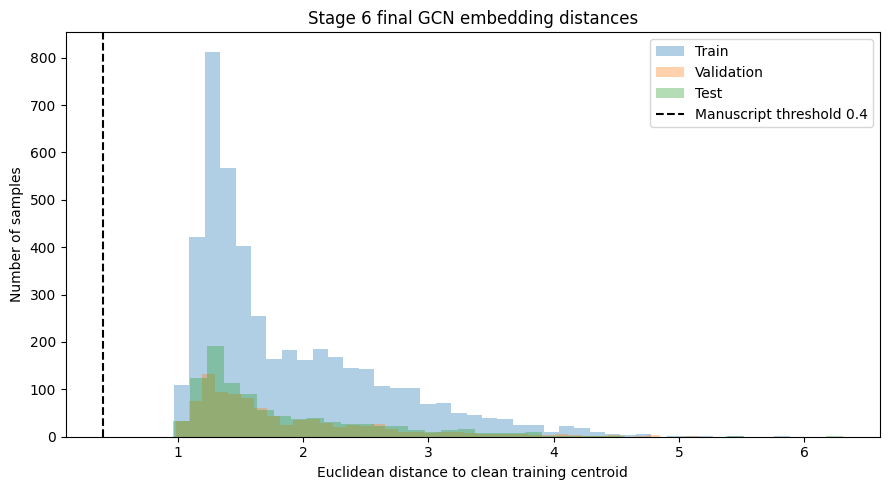

In [10]:
plt.figure(figsize=(9,5))
for split,mask in [("Train",train_mask),("Validation",val_mask),("Test",test_mask)]:
    mu=H_rebuilt[train_mask].mean(axis=0)
    d=np.linalg.norm(H_rebuilt[mask]-mu[None,:],axis=1)
    plt.hist(d,bins=40,alpha=.35,label=split)
plt.axvline(.4,color="black",linestyle="--",label="Manuscript threshold 0.4")
plt.xlabel("Euclidean distance to clean training centroid")
plt.ylabel("Number of samples")
plt.title("Stage 6 final GCN embedding distances")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Save diagnostic report

In [11]:
OUT=Path("/content/Stage8A_Diagnostic_Outputs")
OUT.mkdir(parents=True,exist_ok=True)
representation_summary.to_csv(OUT/"representation_scale_summary.csv",index=False)
distance_summary.to_csv(OUT/"centroid_distance_comparison.csv",index=False)
dgi_diag.to_csv(OUT/"dgi_discriminator_diagnostic.csv",index=False)

config={
 "purpose":"diagnostic only; no threshold tuning and no detection claims",
 "manuscript_formula":"S_i = ||h_i - mu||_2",
 "manuscript_threshold":0.4,
 "centroid_interpretations_reported":["clean training samples","all clean samples"],
 "representations_reported":["CNN node features","GCN first-layer raw","GCN first-layer ReLU","final Stage6 GCN output"],
 "stage6_embedding_reconstruction_max_abs_difference":maxdiff,
 "stage5_graph_nodes":int(N),
 "stage5_graph_undirected_edges":int(A.nnz//2),
 "note":"Manuscript does not fully specify centroid subset or alternative representation layer. Diagnostic comparisons do not select a replacement method."
}
with open(OUT/"diagnostic_config.json","w") as f: json.dump(config,f,indent=2)
zip_path="/content/Stage8A_Diagnostic_Outputs.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for p in OUT.iterdir():
        if p.is_file(): z.write(p,arcname=p.name)
print("Created:",zip_path)
files.download(zip_path)

Created: /content/Stage8A_Diagnostic_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Return the results for review

Upload **`Stage8A_Diagnostic_Outputs.zip`** in this ChatGPT conversation.

Do not change the manuscript threshold or replace the Euclidean anomaly score based only on these diagnostic comparisons. We will review the results first and decide which interpretation is supported by the manuscript and implementation records.